<a href="https://colab.research.google.com/github/Cheikhcisse1/projet_FN/blob/main/EcoTechCeram_analyse_predictive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eco-Tech Ceram — Prédire, expliquer et prévoir les ventes

**Problématique** : Eco-Tech Ceram ne vend pas assez pour couvrir ses charges fixes et salariales.
Comment prévoir le chiffre d'affaires à court terme à partir du pipeline commercial, et expliquer les facteurs
qui font aboutir ou échouer les opportunités, afin de cibler les actions qui ramènent l'entreprise au point mort ?

> ⚠️ **Données fictives** (générées par `data/generer_donnees.py`). Les résultats illustrent la méthode,
> pas la situation réelle de l'entreprise. Les montants et les charges fixes sont à remplacer par les vraies données.

**Plan**
1. Chargement et contrôle qualité
2. Analyse exploratoire
3. Nettoyage et construction de variables
4. Découpage temporel
5. Modélisation : régression logistique, CatBoost, calibration
6. Évaluation
7. Explicabilité (SHAP)
8. Prévision du CA et écart au point mort
9. Priorisation des opportunités en cours
10. Conclusions et recommandations

In [2]:
%pip install catboost shap -q

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ml
import shap
#
from catboost import CatBoostClassifier, Pool
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# chargement des données
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

# Paramètres métier (À REMPLACER par les vrais chiffres de la direction)
CHARGES_FIXES_ANNUELLES_EUR = 35_000_000
HORIZON_MOIS = 6
DATE_DEBUT_TEST = "2025-01-01"

## 1. Chargement et contrôle qualité

In [5]:
df = pd.read_csv("/content/ecotechceram_opportunites_fictives.csv", sep=";", decimal=",",
                 encoding="utf-8-sig", parse_dates=["date_creation", "date_cloture"])
print(f'la taille des données {df.shape}')
df.head()

la taille des données (2500, 33)


,id_opportunite,date_creation,date_cloture,duree_cycle_jours,region,secteur,taille_entreprise,effectif_site,conso_gaz_GWh_an,temperature_process_C,type_solution,offre,puissance_MW,montant_devis_EUR,remise_accordee_pct,prix_chaleur_EUR_MWh,prix_gaz_marche_EUR_MWh,economie_annuelle_estimee_EUR,temps_retour_ans,co2_evite_t_an,aide_publique_eligible,source_lead,commercial,nb_rdv,nb_relances,visite_site,etude_faisabilite,delai_reponse_devis_jours,concurrent_present,statut,motif_perte,ca_signe_EUR,marge_brute_pct
0,OPP-00001,2021-01-02,2021-07-01,180.0,Grand Est,Céramique,PME,121.0,NaN,928.0,Récupération chaleur fatale,Vente équipement,0.88,365000.0,8.3,NaN,32.5,14800.0,24.7,260.0,1,Site web,COM_03,3,1.0,1,0,10.0,1,Perdue,Pas de financement,0.0,NaN
1,OPP-00002,2021-01-03,2021-04-01,88.0,Grand Est,Métallurgie,PME,246.0,5.8,826.0,Récupération chaleur fatale,Vente équipement,0.46,185000.0,8.6,NaN,37.6,30500.0,6.1,464.0,1,Salon professionnel,COM_03,4,3.0,0,1,8.0,1,Perdue,NaN,0.0,NaN
2,OPP-00003,2021-01-03,2021-09-19,259.0,Occitanie,Céramique,PME,146.0,5.6,1240.0,Eco-Stock,Vente équipement,0.44,338000.0,4.3,NaN,35.8,5000.0,25.0,297.0,0,Prospection directe,COM_05,4,6.0,1,1,17.0,1,Perdue,Projet reporté / budget gelé,0.0,NaN
3,OPP-00004,2021-01-03,2021-07-08,186.0,Pays de la Loire,Céramique,ETI,1448.0,19.7,1119.0,Hybridation E-Burner,Vente de chaleur,1.93,751000.0,5.5,49.6,34.1,5000.0,25.0,1608.0,1,Recommandation client,COM_04,3,4.0,0,0,20.0,1,Perdue,Temps de retour trop long,0.0,NaN
4,OPP-00005,2021-01-04,2021-06-04,151.0,Occitanie,Céramique,ETI,1260.0,26.1,1100.0,Eco-Stock,Vente de chaleur,1.33,781000.0,1.1,56.7,38.3,44000.0,17.8,1501.0,0,Salon professionnel,COM_01,1,4.0,0,1,7.0,1,Perdue,Choix d'un concurrent,0.0,NaN


In [6]:
qualite = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "pct_manquant": (df.isna().mean() * 100).round(1),
    "nb_distinct": df.nunique(),
}).sort_values("pct_manquant", ascending=False)
qualite.head(12)

,type,pct_manquant,nb_distinct
marge_brute_pct,float64,70.2,249
prix_chaleur_EUR_MWh,float64,63.6,322
motif_perte,object,44.6,8
duree_cycle_jours,float64,7.3,408
date_cloture,datetime64[ns],7.3,1380
conso_gaz_GWh_an,float64,6.3,864
temperature_process_C,float64,4.8,1020
delai_reponse_devis_jours,float64,4.8,82
effectif_site,float64,4.6,1198
nb_relances,float64,3.3,14


Les valeurs manquantes sont limitées (< 7 %) et concernent des champs de saisie CRM
(consommation de gaz, température du procédé, effectif). `date_cloture` et `duree_cycle_jours` sont vides
pour les opportunités **en cours**, c'est attendu.

In [18]:
colonne = pd.DataFrame({'types_colonnes':df.dtypes})
display(colonne)


,types_colonnes
id_opportunite,object
date_creation,datetime64[ns]
date_cloture,datetime64[ns]
duree_cycle_jours,float64
region,object
secteur,object
taille_entreprise,object
effectif_site,float64
conso_gaz_GWh_an,float64
temperature_process_C,float64


In [20]:
display(df["statut"].value_counts())

,count
statut,
Perdue,1574
Gagnée,744
En cours,182


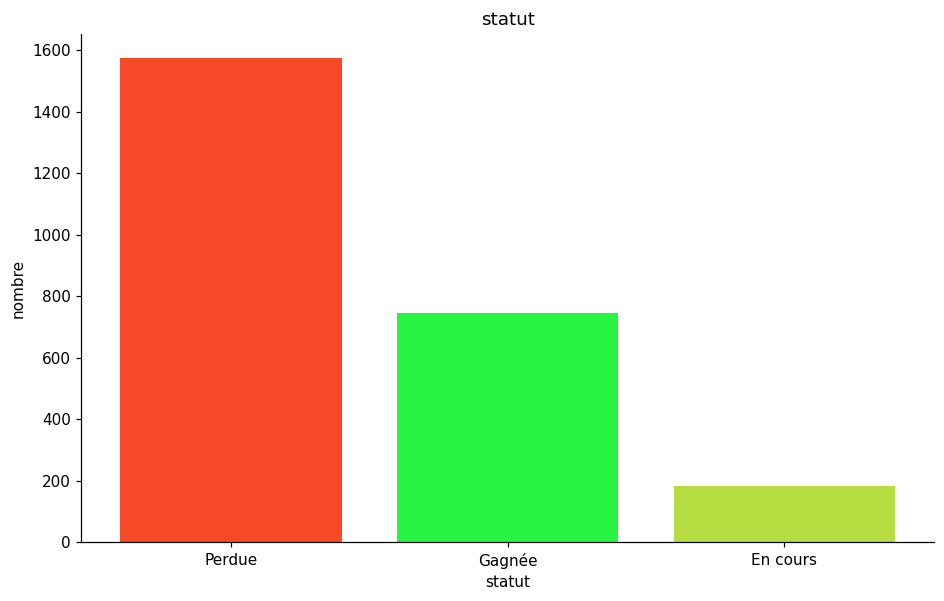

In [26]:
plt.figure(figsize=(10,6))
plt.bar(x=df["statut"].value_counts().index, height=df["statut"].value_counts(), color= ["#F54927","#27F542","#B5DC41"])
plt.xticks(rotation=0)
plt.title("statut")
plt.xlabel("statut")
plt.ylabel("nombre")
plt.show()

## 2. Analyse exploratoire

In [27]:
print(df["statut"].value_counts())
clos = df[df["statut"] != "En cours"]
print(f"\nTaux de signature global : {(clos['statut'] == 'Gagnée').mean():.1%}")

statut
Perdue      1574
Gagnée       744
En cours     182
Name: count, dtype: int64

Taux de signature global : 32.1%


In [37]:
new_df = pd.DataFrame({
    'date_creation':clos['date_creation'],
    'date_cloture':clos['date_cloture'],
    'duree_cycle_jours':clos['duree_cycle_jours'],
    'ca_signe_EUR':clos['ca_signe_EUR'],
    'statut':clos['statut'],
})
display(new_df.head(2))

,date_creation,date_cloture,duree_cycle_jours,ca_signe_EUR,statut
0,2021-01-02,2021-07-01,180.0,0.0,Perdue
1,2021-01-03,2021-04-01,88.0,0.0,Perdue


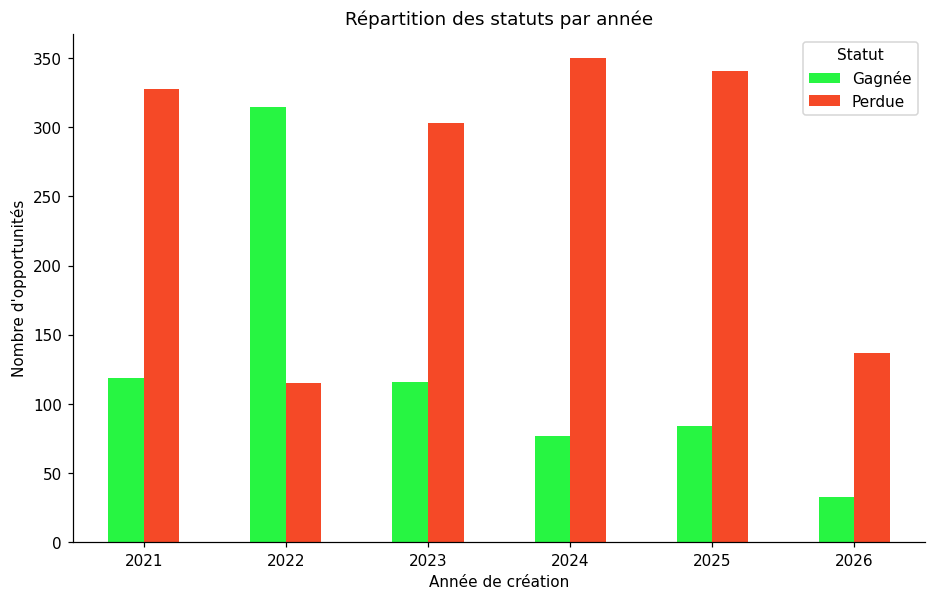

In [39]:
# Visualisation de la répartition des statuts par année
statut_par_annee = pd.crosstab(new_df["date_creation"].dt.year, new_df["statut"])
statut_par_annee.plot(kind="bar", figsize=(10,6), color=["#27F542", "#F54927"])
plt.xticks(rotation=0)
plt.title("Répartition des statuts par année")
plt.xlabel("Année de création")
plt.ylabel("Nombre d'opportunités")
plt.legend(title="Statut")
plt.show()

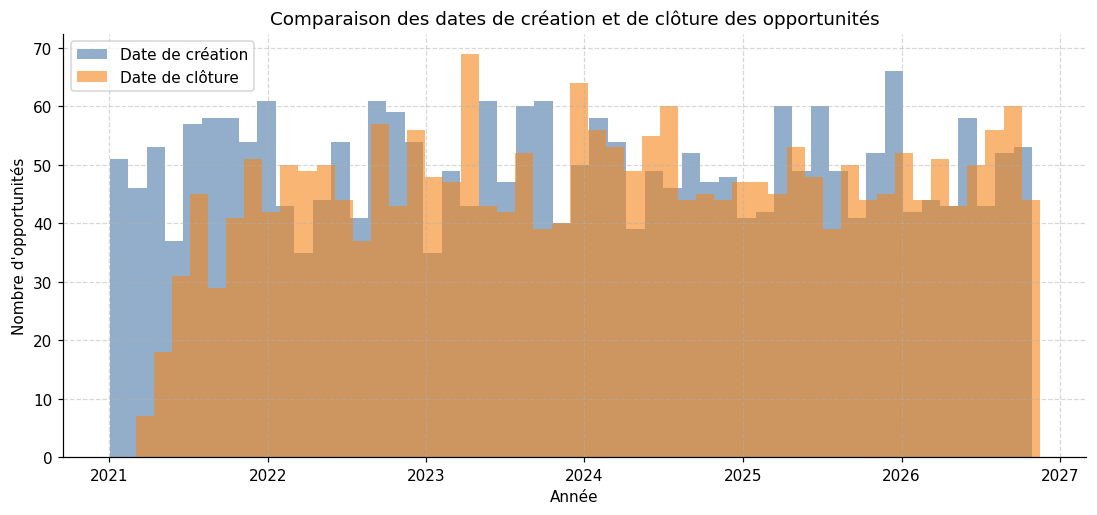

In [40]:
import matplotlib.pyplot as plt

# Configuration de la figure
plt.figure(figsize=(12, 5))

# Tracé des histogrammes pour comparer les distributions temporelles
plt.hist(df["date_creation"], bins=50, alpha=0.6, label="Date de création", color="#4C78A8")
plt.hist(df["date_cloture"].dropna(), bins=50, alpha=0.6, label="Date de clôture", color="#F58518")

# Personnalisation
plt.title("Comparaison des dates de création et de clôture des opportunités")
plt.xlabel("Année")
plt.ylabel("Nombre d'opportunités")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [34]:
g = df[df["statut"] == "Gagnée"].copy()
display(g.head(2))
g["marge_EUR"] = g["ca_signe_EUR"] * g["marge_brute_pct"] / 100
annuel = g.groupby(g["date_cloture"].dt.year).agg(ca_signe=("ca_signe_EUR", "sum"), marge=("marge_EUR", "sum"))
annuel = annuel / 1e6
print("------"*65)
print(annuel)

,id_opportunite,date_creation,date_cloture,duree_cycle_jours,region,secteur,taille_entreprise,effectif_site,conso_gaz_GWh_an,temperature_process_C,type_solution,offre,puissance_MW,montant_devis_EUR,remise_accordee_pct,prix_chaleur_EUR_MWh,prix_gaz_marche_EUR_MWh,economie_annuelle_estimee_EUR,temps_retour_ans,co2_evite_t_an,aide_publique_eligible,source_lead,commercial,nb_rdv,nb_relances,visite_site,etude_faisabilite,delai_reponse_devis_jours,concurrent_present,statut,motif_perte,ca_signe_EUR,marge_brute_pct
9,OPP-00010,2021-01-07,2022-05-26,504.0,Occitanie,Verre,Grand groupe,1859.0,135.2,NaN,Récupération chaleur fatale,Vente équipement,9.65,4071000.0,0.0,NaN,46.2,877600.0,4.6,10854.0,0,Salon professionnel,COM_04,5,4.0,1,0,19.0,0,Gagnée,NaN,4071000.0,33.8
12,OPP-00013,2021-01-10,2022-02-25,411.0,Occitanie,Céramique,Grand groupe,2959.0,87.8,1011.0,Récupération chaleur fatale,Vente de chaleur,7.33,2390000.0,3.2,33.7,46.0,516900.0,4.6,6422.0,0,Prospection directe,COM_01,4,8.0,0,0,11.0,0,Gagnée,NaN,2313500.0,28.5


------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
              ca_signe      marge
date_cloture                     
2021           47.1895  11.451876
2022          227.8655  54.746842
2023          268.5909  67.622683
2024          106.4985  25.456872
2025           57.7652  14.794420
2026           69.9148  16.956634


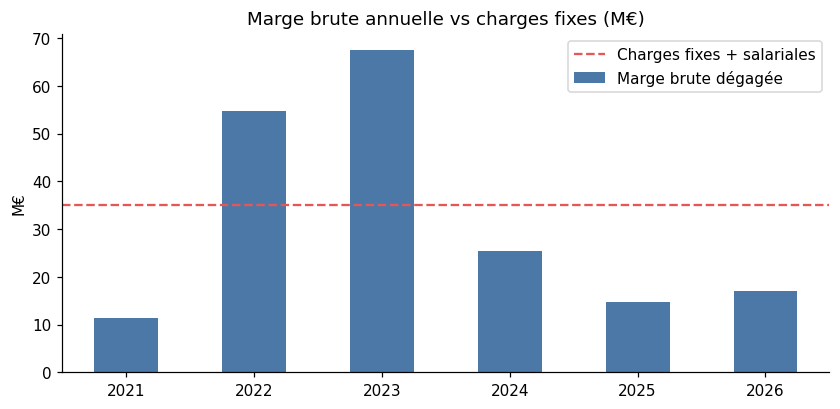

,ca_signe,marge
date_cloture,,
2021,47.2,11.5
2022,227.9,54.7
2023,268.6,67.6
2024,106.5,25.5
2025,57.8,14.8
2026,69.9,17.0


In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
annuel["marge"].plot(kind="bar", ax=ax, color="#4C78A8", label="Marge brute dégagée")
ax.axhline(CHARGES_FIXES_ANNUELLES_EUR / 1e6, color="#E45756", ls="--", label="Charges fixes + salariales")
ax.set(title="Marge brute annuelle vs charges fixes (M€)", xlabel="", ylabel="M€")
ax.legend()
plt.xticks(rotation=0)
plt.show()
annuel.round(1)

**Lecture** : la marge couvrait largement les charges en 2022-2023 (prix du gaz élevé = projets très rentables
pour les clients), mais **depuis 2024 elle ne les couvre plus**. C'est le « on ne vend pas assez » du directeur.

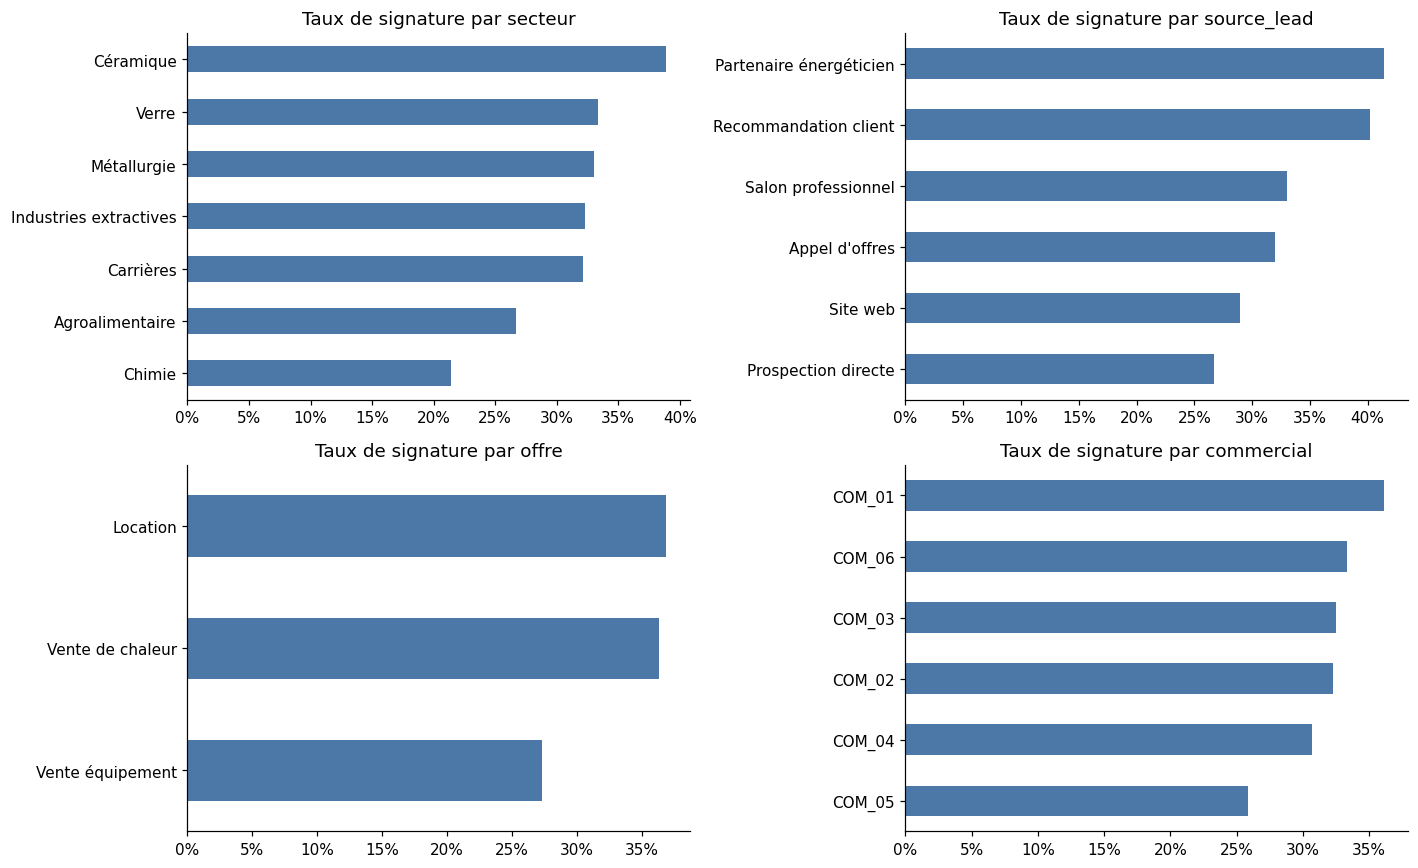

In [41]:
clos = df[df["statut"] != "En cours"].assign(gagne=lambda d: (d["statut"] == "Gagnée").astype(int))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, ["secteur", "source_lead", "offre", "commercial"]):
    t = clos.groupby(col)["gagne"].mean().sort_values()
    t.plot(kind="barh", ax=ax, color="#4C78A8")
    ax.set(title=f"Taux de signature par {col}", xlabel="", ylabel="")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.show()

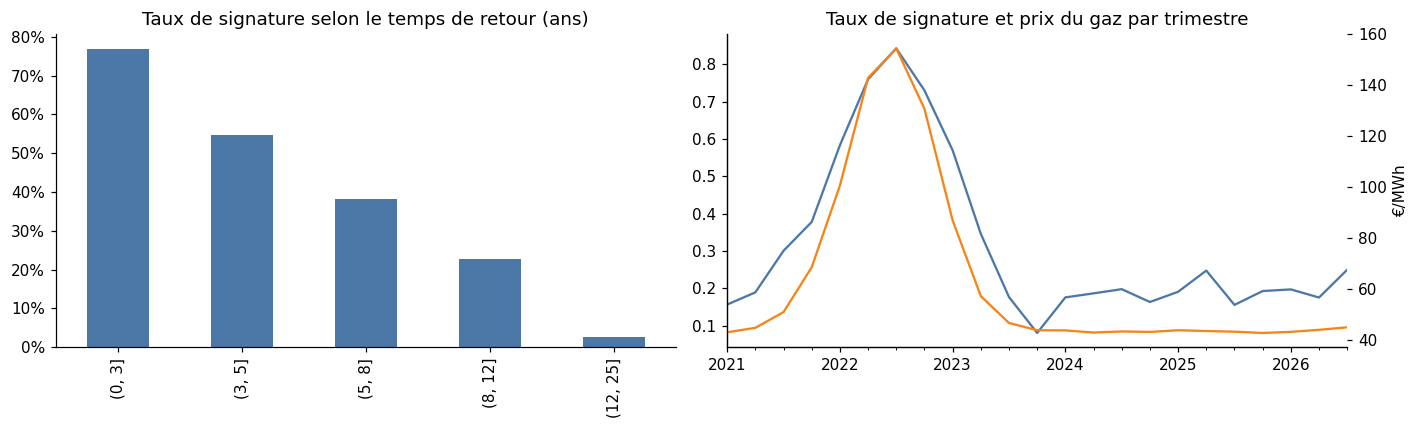

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
clos["tranche_retour"] = pd.cut(clos["temps_retour_ans"], [0, 3, 5, 8, 12, 25])
clos.groupby("tranche_retour", observed=True)["gagne"].mean().plot(kind="bar", ax=ax[0], color="#4C78A8")
ax[0].set(title="Taux de signature selon le temps de retour (ans)", xlabel="", ylabel="")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))

clos.groupby(clos["date_creation"].dt.to_period("Q"))["gagne"].mean().plot(ax=ax[1], color="#4C78A8", label="Taux de signature")
ax2 = ax[1].twinx()
clos.groupby(clos["date_creation"].dt.to_period("Q"))["prix_gaz_marche_EUR_MWh"].mean().plot(ax=ax2, color="#F58518", label="Prix du gaz")
ax[1].set(title="Taux de signature et prix du gaz par trimestre", xlabel="")
ax2.set_ylabel("€/MWh")
plt.tight_layout()
plt.show()

In [43]:
perdues = df[(df["statut"] == "Perdue") & df["motif_perte"].notna() & (df["motif_perte"] != "")]
perdues["motif_perte"].value_counts(normalize=True).mul(100).round(1).to_frame("% des pertes renseignées")

,% des pertes renseignées
motif_perte,
Temps de retour trop long,31.8
Prix trop élevé,15.1
Choix d'un concurrent,12.0
Projet reporté / budget gelé,11.3
Pas de financement,10.8
Prix du gaz jugé trop bas,9.1
Risque technique perçu,6.2
Pas de réponse du client,3.6


**Premiers enseignements**
- Le **temps de retour sur investissement** est le premier frein : au-delà de 8 ans, le taux de signature s'effondre.
- Les ventes suivent le **prix du gaz** : quand il baisse, l'intérêt économique des projets baisse.
- Les **recommandations** et **partenaires énergéticiens** convertissent mieux que la prospection directe.

## 3. Nettoyage et construction de variables

In [44]:
CAT = ["region", "secteur", "taille_entreprise", "type_solution", "offre", "source_lead", "commercial"]
NUM = ["effectif_site", "conso_gaz_GWh_an", "temperature_process_C", "puissance_MW", "montant_devis_EUR",
       "remise_accordee_pct", "prix_gaz_marche_EUR_MWh", "economie_annuelle_estimee_EUR", "temps_retour_ans",
       "co2_evite_t_an", "aide_publique_eligible", "nb_rdv", "nb_relances", "visite_site", "etude_faisabilite",
       "delai_reponse_devis_jours", "concurrent_present",
       "log_montant_devis", "ratio_economie_devis", "mois_creation", "trimestre_creation", "est_vente_chaleur"]

# Variables connues seulement APRÈS la clôture -> fuite d'information, exclues
FUITE = ["motif_perte", "ca_signe_EUR", "marge_brute_pct", "date_cloture", "duree_cycle_jours", "statut"]

d = df.drop_duplicates("id_opportunite").copy()
d["log_montant_devis"] = np.log1p(d["montant_devis_EUR"])
d["ratio_economie_devis"] = d["economie_annuelle_estimee_EUR"] / d["montant_devis_EUR"]
d["mois_creation"] = d["date_creation"].dt.month
d["trimestre_creation"] = d["date_creation"].dt.quarter
d["est_vente_chaleur"] = (d["offre"] == "Vente de chaleur").astype(int)
d["cible"] = d["statut"].map({"Gagnée": 1, "Perdue": 0})
d[CAT + NUM + ["cible"]].describe(include="all").T.head(10)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
region,2500,12,Occitanie,472,NaN,NaN,NaN,NaN,NaN,NaN,NaN
secteur,2500,7,Céramique,638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
taille_entreprise,2500,3,PME,1097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_solution,2500,4,Récupération chaleur fatale,1028,NaN,NaN,NaN,NaN,NaN,NaN,NaN
offre,2500,3,Vente équipement,1195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_lead,2500,6,Prospection directe,708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commercial,2500,6,COM_01,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
effectif_site,2385.0,NaN,NaN,NaN,706.295597,716.729625,20.0,147.0,432.0,1093.0,2994.0
conso_gaz_GWh_an,2342.0,NaN,NaN,NaN,38.106789,47.13913,1.4,10.2,21.5,46.275,458.3
temperature_process_C,2381.0,NaN,NaN,NaN,693.966401,412.832037,81.0,250.0,724.0,1069.0,1498.0


## 4. Découpage temporel

On n'utilise **pas** de découpage aléatoire : le marché évolue (prix du gaz), donc on entraîne sur le passé et on teste
sur la période la plus récente, comme en conditions réelles.
- **Train** : opportunités créées avant 2025 (les 20 % les plus récentes servent de validation)
- **Test** : opportunités créées à partir de 2025
- **En cours** : non clôturées → à scorer pour la prévision

In [45]:
clos = d[d["cible"].notna()].sort_values("date_creation")
en_cours = d[d["cible"].isna()].copy()
train = clos[clos["date_creation"] < DATE_DEBUT_TEST]
test = clos[clos["date_creation"] >= DATE_DEBUT_TEST]
coupe = int(len(train) * 0.8)
fit, val = train.iloc[:coupe], train.iloc[coupe:]

X = lambda t: t[CAT + NUM]
y = lambda t: t["cible"].astype(int)
print(f"train={len(train)} (fit={len(fit)}, val={len(val)}) | test={len(test)} | en cours={len(en_cours)}")
print(f"Taux de signature : train={y(train).mean():.1%} | test={y(test).mean():.1%}")

train=1723 (fit=1378, val=345) | test=595 | en cours=182
Taux de signature : train=36.4% | test=19.7%


⚠️ Le taux de signature passe de 36 % à 20 % entre train et test : c'est une **dérive** du marché.
Le modèle devra être réentraîné régulièrement.

## 5. Modélisation

### 5.1 Régression logistique (modèle de référence, interprétable)

In [46]:
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", drop="first"))]), CAT),
])
logit = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"))])
logit.fit(X(train), y(train))

coefs = pd.DataFrame({"variable": logit.named_steps["pre"].get_feature_names_out(),
                      "coef": logit.named_steps["clf"].coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"]).round(2)
coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).head(12)

,variable,coef,odds_ratio
8,num__temps_retour_ans,-1.996057,0.14
35,cat__secteur_Céramique,0.825830,2.28
38,cat__secteur_Verre,0.676671,1.97
45,cat__offre_Vente équipement,-0.667196,0.51
54,cat__commercial_COM_05,-0.666330,0.51
40,cat__taille_entreprise_PME,-0.601337,0.55
37,cat__secteur_Métallurgie,0.595190,1.81
46,cat__source_lead_Partenaire énergéticien,0.523470,1.69
29,cat__region_Occitanie,0.509832,1.67
47,cat__source_lead_Prospection directe,-0.490337,0.61


**Lecture des odds ratios** (variables numériques standardisées) : un odds ratio < 1 diminue les chances de signer.
Par exemple, un écart-type de temps de retour en plus divise fortement la probabilité de signature.

### 5.2 CatBoost (gère nativement les catégorielles et les non-linéarités)

In [47]:
cb = CatBoostClassifier(iterations=800, learning_rate=0.03, depth=5, l2_leaf_reg=5, eval_metric="AUC",
                        cat_features=CAT, random_seed=SEED, verbose=False, allow_writing_files=False)
cb.fit(X(fit), y(fit), eval_set=(X(val), y(val)), early_stopping_rounds=100, use_best_model=True)
print("Meilleure itération :", cb.get_best_iteration())

Meilleure itération : 191


### 5.3 Calibration
Les probabilités servent à prévoir le CA : elles doivent être **justes**, pas seulement bien ordonnées.

In [50]:
cb_cal = CalibratedClassifierCV(FrozenEstimator(cb), method="isotonic").fit(X(val), y(val))

## 6. Évaluation sur le test (2025-2026)

In [51]:
probas = {"Régression logistique": logit.predict_proba(X(test))[:, 1],
          "CatBoost": cb.predict_proba(X(test))[:, 1],
          "CatBoost calibré": cb_cal.predict_proba(X(test))[:, 1]}

def metriques(nom, yt, p):
    pr = (p >= 0.5).astype(int)
    return {"modèle": nom, "AUC_ROC": roc_auc_score(yt, p), "AUC_PR": average_precision_score(yt, p),
            "Brier": brier_score_loss(yt, p), "Précision": precision_score(yt, pr, zero_division=0),
            "Rappel": recall_score(yt, pr), "F1": f1_score(yt, pr),
            "taux_réel": yt.mean(), "proba_moyenne": p.mean()}

pd.DataFrame([metriques(n, y(test), p) for n, p in probas.items()]).round(3)

,modèle,AUC_ROC,AUC_PR,Brier,Précision,Rappel,F1,taux_réel,proba_moyenne
0,Régression logistique,0.872,0.644,0.111,0.597,0.607,0.602,0.197,0.240
1,CatBoost,0.853,0.584,0.116,0.744,0.274,0.400,0.197,0.177
2,CatBoost calibré,0.850,0.544,0.115,0.717,0.282,0.405,0.197,0.205


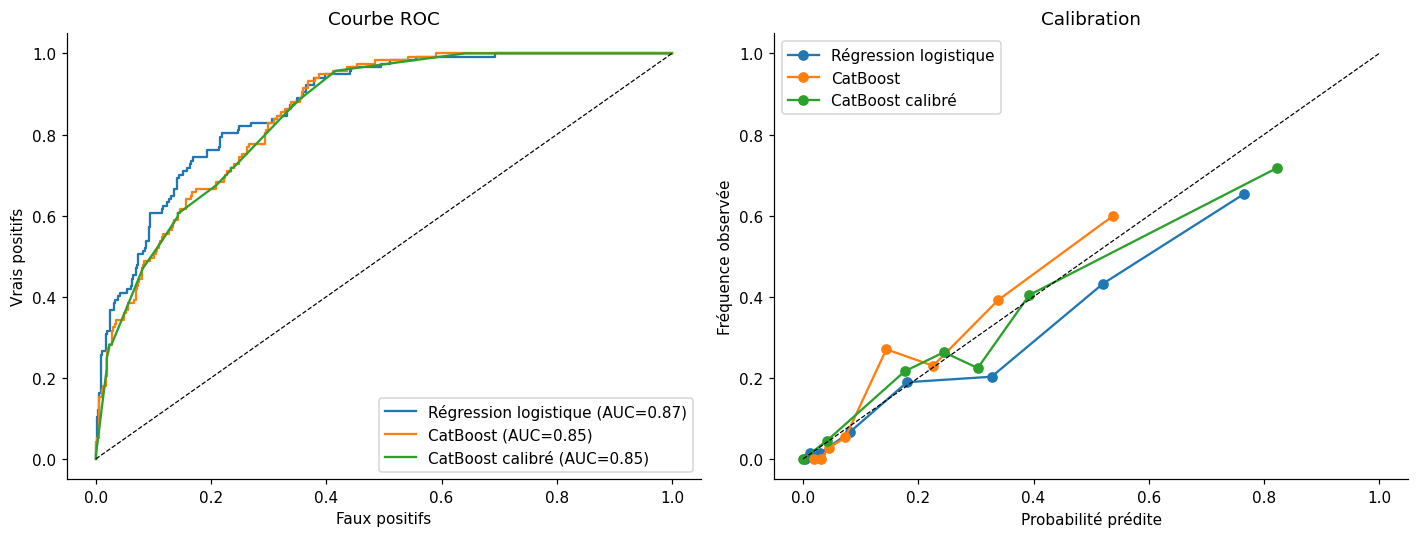

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nom, p in probas.items():
    fpr, tpr, _ = roc_curve(y(test), p)
    ax[0].plot(fpr, tpr, label=f"{nom} (AUC={roc_auc_score(y(test), p):.2f})")
    fr, mp = calibration_curve(y(test), p, n_bins=8, strategy="quantile")
    ax[1].plot(mp, fr, marker="o", label=nom)
for a, t, xl, yl in [(ax[0], "Courbe ROC", "Faux positifs", "Vrais positifs"),
                     (ax[1], "Calibration", "Probabilité prédite", "Fréquence observée")]:
    a.plot([0, 1], [0, 1], "k--", lw=0.8); a.set(title=t, xlabel=xl, ylabel=yl); a.legend()
plt.tight_layout()
plt.show()

**Choix du modèle** : les trois modèles sont proches (AUC ≈ 0,85-0,87). La régression logistique fait légèrement mieux
ici, ce qui est logique car les données fictives ont été simulées avec une relation linéaire. Sur les vraies données,
CatBoost peut prendre l'avantage. On garde **CatBoost calibré** pour la prévision (probabilités les mieux calibrées en
moyenne : 19,8 % prédit vs 19,7 % réel) et **SHAP** pour l'explication.

## 7. Explicabilité (SHAP)

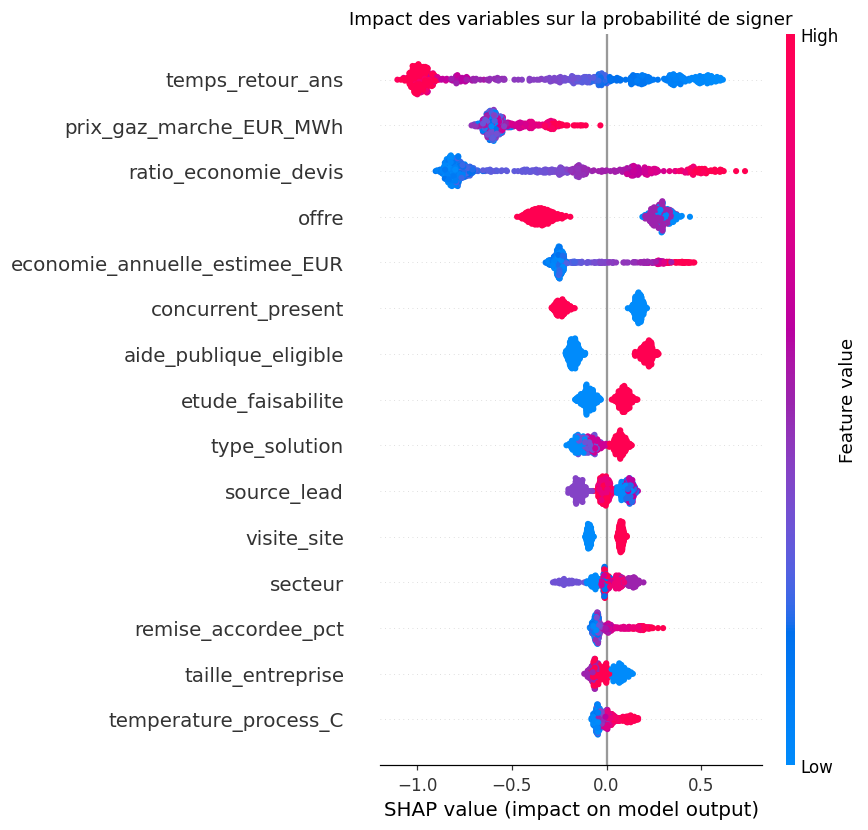

,variable,importance
15,temps_retour_ans,0.560
13,prix_gaz_marche_EUR_MWh,0.528
25,ratio_economie_devis,0.516
4,offre,0.315
14,economie_annuelle_estimee_EUR,0.245
23,concurrent_present,0.198
17,aide_publique_eligible,0.191
21,etude_faisabilite,0.095
3,type_solution,0.093
5,source_lead,0.085


In [53]:
sv = cb.get_feature_importance(Pool(X(test), cat_features=CAT), type="ShapValues")[:, :-1]
imp = pd.DataFrame({"variable": CAT + NUM, "importance": np.abs(sv).mean(0)}).sort_values("importance", ascending=False)

X_aff = X(test).copy()
for c in CAT:
    X_aff[c] = X_aff[c].astype("category").cat.codes
shap.summary_plot(sv, X_aff, max_display=15, show=False)
plt.title("Impact des variables sur la probabilité de signer")
plt.show()
imp.head(10).round(3)

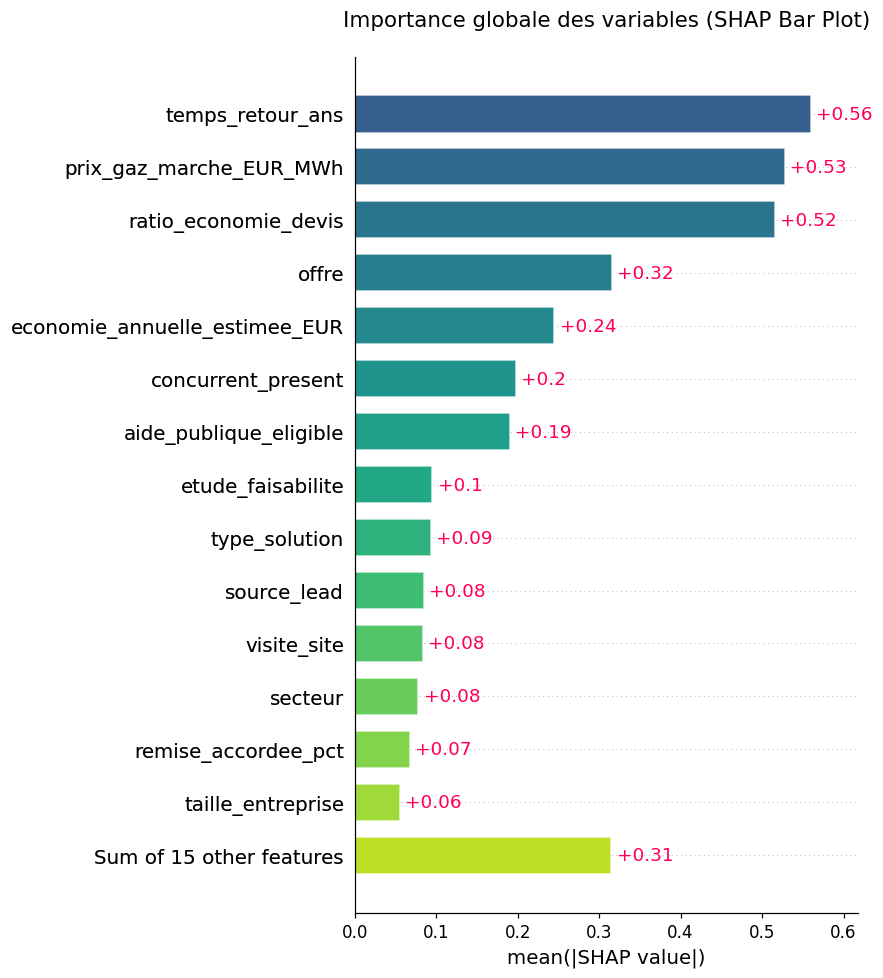

In [60]:
import matplotlib.cm as cm
# Créer un objet Explanation requis par l'API moderne de SHAP pour le tracé en barres
explanation = shap.Explanation(
    values=sv,
    data=X(test),
    feature_names=CAT + NUM
)

plt.figure(figsize=(10, 6))
# Générer le graphique SHAP
shap.plots.bar(explanation, max_display=15, show=False)

# Personnaliser les couleurs des barres individuelles
ax = plt.gca()
# Récupérer les rectangles (barres) dessinés
rects = [patch for patch in ax.patches if isinstance(patch, plt.Rectangle)]

# Appliquer un dégradé de couleurs distinctes (palette viridis)
colors = cm.viridis(np.linspace(0.3, 0.9, len(rects)))
for i, rect in enumerate(rects):
    if i < len(colors):
        rect.set_facecolor(colors[i])

plt.title("Importance globale des variables (SHAP Bar Plot)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

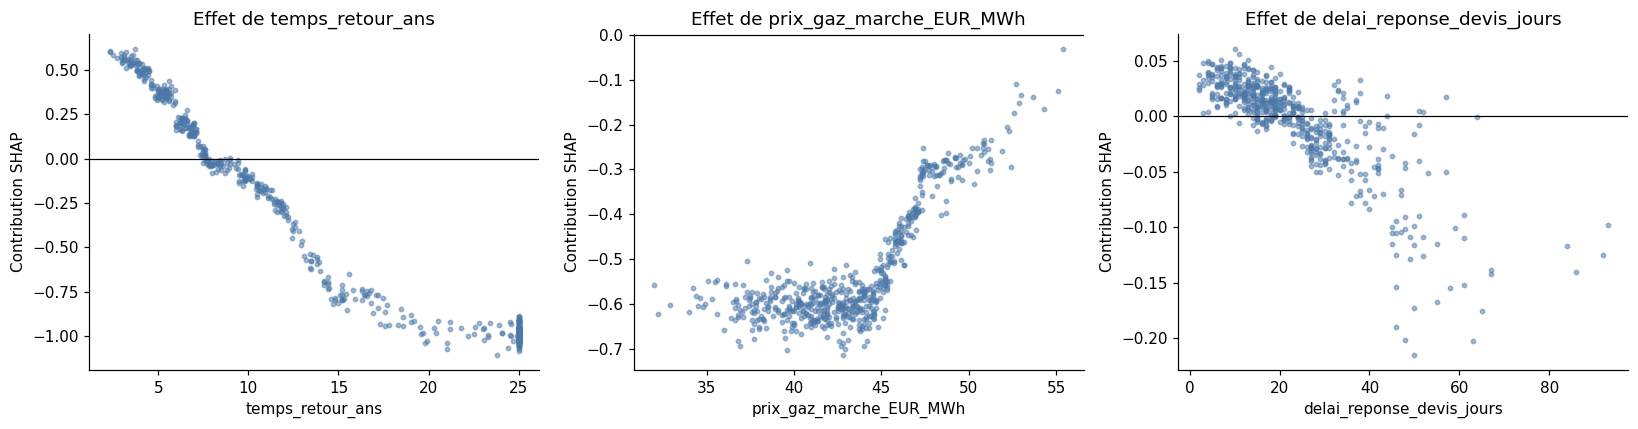

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, ["temps_retour_ans", "prix_gaz_marche_EUR_MWh", "delai_reponse_devis_jours"]):
    i = (CAT + NUM).index(var)
    ax.scatter(X(test)[var], sv[:, i], s=8, alpha=0.5, color="#4C78A8")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"Effet de {var}", xlabel=var, ylabel="Contribution SHAP")
plt.tight_layout()
plt.show()

**Ce qui fait signer (ou perdre) une affaire**
1. **Temps de retour sur investissement** : au-delà d'environ 8 ans, l'effet devient fortement négatif.
2. **Prix du gaz** : plus il est haut, plus le projet est attractif — facteur externe non maîtrisable.
3. **Ratio économie / devis** et **type d'offre** : la vente de chaleur (zéro investissement) convertit mieux.
4. **Concurrent présent** et **aide publique** : leviers sur lesquels l'équipe commerciale peut agir
   (monter les dossiers d'aide systématiquement, se différencier tôt).
5. **Visite du site** et **étude de faisabilité** : l'investissement avant-vente paie.

## 8. Prévision du CA à court terme et écart au point mort

In [55]:
p_ec = cb_cal.predict_proba(X(en_cours))[:, 1]
montant_net = (en_cours["montant_devis_EUR"] * (1 - en_cours["remise_accordee_pct"] / 100)).values
ca_attendu = (p_ec * montant_net).sum()

rng = np.random.default_rng(SEED)
sims = (rng.random((5000, len(p_ec))) < p_ec) @ montant_net   # Monte-Carlo : chaque affaire signe ou non

marge = d.loc[d["statut"] == "Gagnée", "marge_brute_pct"].mean() / 100
charges_horizon = CHARGES_FIXES_ANNUELLES_EUR * HORIZON_MOIS / 12
ca_necessaire = charges_horizon / marge

synthese = pd.Series({
    "Opportunités en cours": len(en_cours),
    "CA attendu (M€)": ca_attendu / 1e6,
    "CA P10 (M€)": np.percentile(sims, 10) / 1e6,
    "CA P90 (M€)": np.percentile(sims, 90) / 1e6,
    "Charges sur l'horizon (M€)": charges_horizon / 1e6,
    "Marge brute moyenne": marge,
    "CA nécessaire au point mort (M€)": ca_necessaire / 1e6,
    "Écart (M€)": (ca_attendu - ca_necessaire) / 1e6,
    "Probabilité de couvrir les charges": (sims * marge >= charges_horizon).mean(),
}).round(3)
synthese

,0
Opportunités en cours,182.000
CA attendu (M€),39.892
CA P10 (M€),31.976
CA P90 (M€),47.795
Charges sur l'horizon (M€),17.500
Marge brute moyenne,0.247
CA nécessaire au point mort (M€),70.920
Écart (M€),-31.028
Probabilité de couvrir les charges,0.000


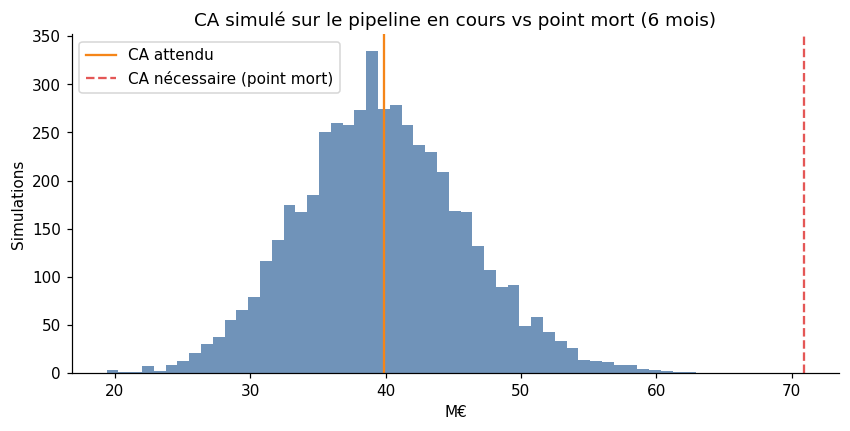

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(sims / 1e6, bins=50, color="#4C78A8", alpha=0.8)
ax.axvline(ca_attendu / 1e6, color="#F58518", label="CA attendu")
ax.axvline(ca_necessaire / 1e6, color="#E45756", ls="--", label="CA nécessaire (point mort)")
ax.set(title=f"CA simulé sur le pipeline en cours vs point mort ({HORIZON_MOIS} mois)", xlabel="M€", ylabel="Simulations")
ax.legend()
plt.show()

Même dans le scénario optimiste (P90), le pipeline actuel ne couvre pas les charges de l'horizon :
**il ne suffit pas de mieux convertir, il faut aussi alimenter le pipeline** (plus d'opportunités, mieux ciblées).

## 9. Priorisation des opportunités en cours

In [56]:
sv_ec = cb.get_feature_importance(Pool(X(en_cours), cat_features=CAT), type="ShapValues")[:, :-1]
cols = np.array(CAT + NUM)

def resume(k, signe, n=3):
    s = sv_ec[k]
    idx = np.argsort(s) if signe < 0 else np.argsort(-s)
    return " | ".join(f"{cols[j]}={X(en_cours).iloc[k, j]}" for j in idx[:n] if s[j] * signe > 0)

prio = pd.DataFrame({
    "id_opportunite": en_cours["id_opportunite"].values,
    "secteur": en_cours["secteur"].values,
    "commercial": en_cours["commercial"].values,
    "montant_net_EUR": montant_net.round(),
    "proba_signature": p_ec.round(3),
    "valeur_attendue_EUR": (montant_net * p_ec).round(),
    "freins": [resume(k, -1) for k in range(len(en_cours))],
    "atouts": [resume(k, +1) for k in range(len(en_cours))],
}).sort_values("valeur_attendue_EUR", ascending=False)
prio.head(10)

,id_opportunite,secteur,commercial,montant_net_EUR,proba_signature,valeur_attendue_EUR,freins,atouts
6,OPP-02128,Industries extractives,COM_03,3903115.0,0.665,2596698.0,prix_gaz_marche_EUR_MWh=46.1 | taille_entrepri...,economie_annuelle_estimee_EUR=562900.0 | offre...
143,OPP-02461,Céramique,COM_05,2778764.0,0.867,2408262.0,prix_gaz_marche_EUR_MWh=37.6 | offre=Vente équ...,temps_retour_ans=4.1 | ratio_economie_devis=0....
116,OPP-02433,Céramique,COM_03,1815512.0,0.867,1573444.0,prix_gaz_marche_EUR_MWh=48.7 | offre=Vente équ...,temps_retour_ans=3.3 | ratio_economie_devis=0....
64,OPP-02363,Verre,COM_01,1629000.0,0.867,1411800.0,prix_gaz_marche_EUR_MWh=44.4 | offre=Vente équ...,ratio_economie_devis=0.39140577041129526 | tem...
52,OPP-02336,Chimie,COM_06,1987021.0,0.667,1324681.0,prix_gaz_marche_EUR_MWh=45.3 | secteur=Chimie ...,economie_annuelle_estimee_EUR=378400.0 | temps...
2,OPP-01958,Céramique,COM_03,2943276.0,0.417,1226365.0,prix_gaz_marche_EUR_MWh=45.8 | concurrent_pres...,economie_annuelle_estimee_EUR=357100.0 | offre...
19,OPP-02222,Céramique,COM_06,1829386.0,0.667,1219591.0,prix_gaz_marche_EUR_MWh=45.1 | concurrent_pres...,economie_annuelle_estimee_EUR=364600.0 | temps...
67,OPP-02367,Carrières,COM_05,4084000.0,0.286,1166857.0,prix_gaz_marche_EUR_MWh=45.6 | concurrent_pres...,economie_annuelle_estimee_EUR=551700.0 | offre...
76,OPP-02383,Agroalimentaire,COM_05,2716000.0,0.417,1131667.0,prix_gaz_marche_EUR_MWh=41.3 | aide_publique_e...,temps_retour_ans=4.4 | economie_annuelle_estim...
51,OPP-02335,Métallurgie,COM_06,1090000.0,0.867,944667.0,prix_gaz_marche_EUR_MWh=40.0 | etude_faisabili...,temps_retour_ans=3.6 | ratio_economie_devis=0....


In [57]:
# Calcul de la probabilité de départ/perte (1 - probabilité de signature)
en_cours["proba_perte"] = 1 - p_ec

# Création d'un tableau d'alerte pour cibler les clients à fort risque de départ/perte
churn_risk = pd.DataFrame({
    "id_opportunite": en_cours["id_opportunite"].values,
    "secteur": en_cours["secteur"].values,
    "montant_devis_EUR": en_cours["montant_devis_EUR"].values,
    "proba_perte": en_cours["proba_perte"].round(3),
    "commercial": en_cours["commercial"].values,
    "principaux_freins": [resume(k, -1) for k in range(len(en_cours))]
}).sort_values("proba_perte", ascending=False)

# Affichage des 10 clients / opportunités les plus à risque
print("=== TOP 10 DES CLIENTS / OPPORTUNITÉS À FORT RISQUE DE PERTE (CHURN) ===")
display(churn_risk.head(10))

=== TOP 10 DES CLIENTS / OPPORTUNITÉS À FORT RISQUE DE PERTE (CHURN) ===


,id_opportunite,secteur,montant_devis_EUR,proba_perte,commercial,principaux_freins
1939,OPP-01940,Agroalimentaire,3154000.0,1.0,COM_01,temps_retour_ans=25.0 | ratio_economie_devis=0...
2139,OPP-02140,Agroalimentaire,553000.0,1.0,COM_01,temps_retour_ans=25.0 | ratio_economie_devis=0...
2165,OPP-02166,Agroalimentaire,493000.0,1.0,COM_05,ratio_economie_devis=0.07484787018255579 | pri...
2202,OPP-02203,Céramique,3617000.0,1.0,COM_04,temps_retour_ans=25.0 | ratio_economie_devis=0...
2135,OPP-02136,Céramique,5963000.0,1.0,COM_01,temps_retour_ans=25.0 | ratio_economie_devis=0...
2235,OPP-02236,Chimie,1602000.0,1.0,COM_05,temps_retour_ans=25.0 | ratio_economie_devis=0...
2299,OPP-02300,Verre,526000.0,1.0,COM_03,temps_retour_ans=25.0 | ratio_economie_devis=0...
2301,OPP-02302,Industries extractives,911000.0,1.0,COM_01,temps_retour_ans=25.0 | ratio_economie_devis=0...
2302,OPP-02303,Industries extractives,288000.0,1.0,COM_06,temps_retour_ans=25.0 | ratio_economie_devis=0...
2303,OPP-02304,Carrières,2741000.0,1.0,COM_05,temps_retour_ans=14.7 | ratio_economie_devis=0...


### Focus sur les Opportunités à Risque de Perte (Analyse de Rétention)
Visualisons les dossiers les plus critiques actuellement en cours afin d'identifier où concentrer les efforts de sauvetage.

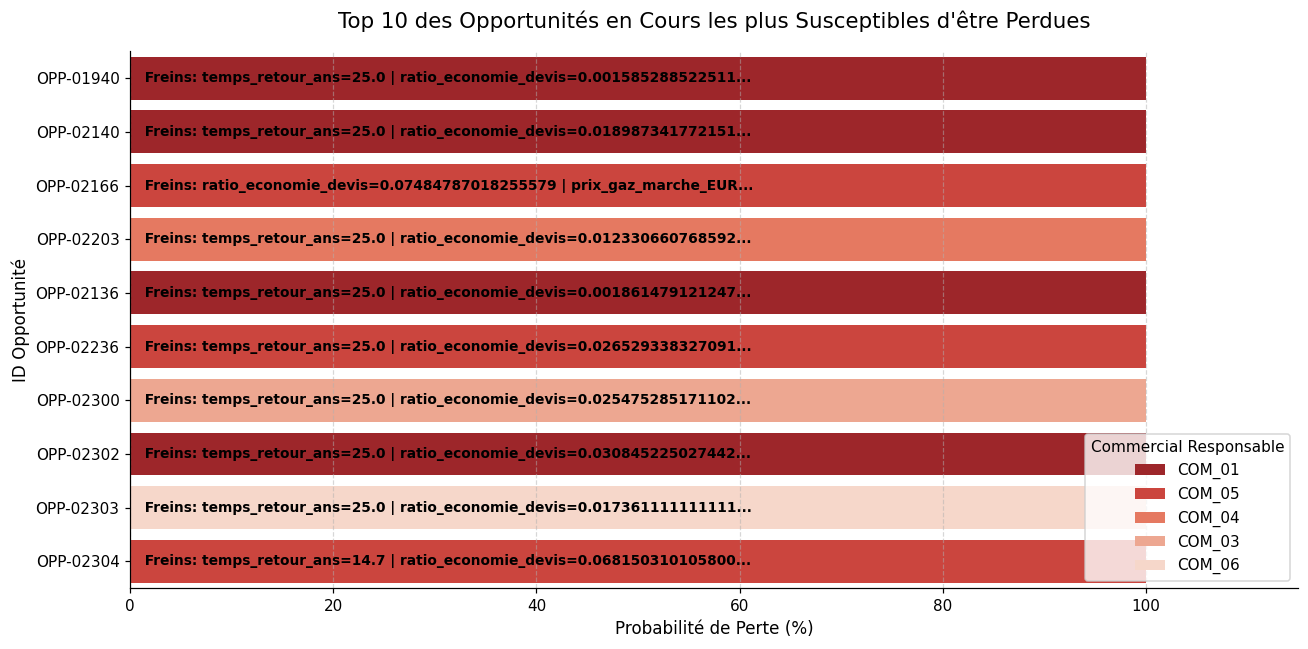

In [62]:
import seaborn as sns

# Sélectionner le top 10 des opportunités avec le plus grand risque de perte
top_risque = churn_risk.head(10).copy()

plt.figure(figsize=(12, 6))
# Créer un graphique à barres horizontales
sns.barplot(
    x=top_risque["proba_perte"] * 100,
    y=top_risque["id_opportunite"],
    hue=top_risque["commercial"],
    palette="Reds_r",
    dodge=False
)

# Ajouter les étiquettes de texte pour afficher les freins directement sur le graphique
for i, (idx, row) in enumerate(top_risque.iterrows()):
    freins_text = row["principaux_freins"]
    # Tronquer le texte si trop long pour l'affichage
    if len(freins_text) > 65:
        freins_text = freins_text[:62] + "..."
    plt.text(
        x=1,
        y=i,
        s=f" Freins: {freins_text}",
        va='center',
        ha='left',
        fontsize=9,
        color='black',
        weight='bold'
    )

plt.title("Top 10 des Opportunités en Cours les plus Susceptibles d'être Perdues", fontsize=14, pad=15)
plt.xlabel("Probabilité de Perte (%)", fontsize=11)
plt.ylabel("ID Opportunité", fontsize=11)
plt.xlim(0, 115) # Laisser de l'espace à droite pour les annotations de freins
plt.legend(title="Commercial Responsable", loc="lower right")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 10. Conclusions et recommandations

| Constat | Recommandation |
|---|---|
| Le temps de retour est le premier frein | Pousser l'offre **vente de chaleur** (zéro investissement) et monter systématiquement les **dossiers d'aide publique** |
| Les ventes dépendent du prix du gaz | Arguments de **sécurisation du prix** (contrat fixe 10-12 ans) et valeur carbone, pas seulement l'économie immédiate |
| Recommandations et partenaires convertissent mieux | Programme de **parrainage client** et partenariats avec énergéticiens |
| Visite + étude de faisabilité augmentent la signature | Les réserver aux opportunités à **forte valeur attendue** (liste de priorisation) |
| Le pipeline actuel ne couvre pas le point mort | **Alimenter le pipeline** : cibler céramique, verre, métallurgie (secteurs à plus fort taux de signature) |

**Limites** : données fictives ; dérive du marché entre train et test ; la prévision suppose que les affaires en cours
se clôturent dans l'horizon (à affiner avec un modèle de survie sur la durée du cycle de vente).

In [63]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from google.colab import files

# 1. Calcul des KPIs généraux
total_pipeline_eur = en_cours["montant_devis_EUR"].sum()
ca_attendu_eur = ca_attendu
ecart_point_mort_eur = ca_attendu - ca_necessaire
churn_moyen_pct = (en_cours["proba_perte"].mean() * 100)

# 2. Construction du Dashboard complet avec Grid multi-graphiques
fig_dash = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "Structure du Pipeline Commercial Global",
        "Taux de Signature Historique par Secteur",
        "Évolution de la Marge Brute vs Charges Fixes (M€)",
        "Top 10 - Clients à Haut Risque de Perte (Churn/Attrition)",
        "Top 10 - Opportunités Prioritaires (Valeur Attendue)",
        "Indicateurs de Performance (KPIs)"
    ),
    specs=[
        [{"type": "pie"}, {"type": "bar"}],
        [{"type": "scatter"}, {"type": "bar"}],
        [{"type": "table"}, {"type": "table"}]
    ],
    vertical_spacing=0.08,
    horizontal_spacing=0.07
)

# --- GRAPH 1 : Répartition Statuts ---
fig_dash.add_trace(
    go.Pie(
        labels=statut_counts.index,
        values=statut_counts.values,
        marker=dict(colors=["#E45756", "#47B39C", "#ECDB54"]),
        hole=0.4,
        textinfo="percent+label"
    ),
    row=1, col=1
)

# --- GRAPH 2 : Taux de Signature par Secteur ---
fig_dash.add_trace(
    go.Bar(
        x=secteur_rates["gagne"] * 100,
        y=secteur_rates["secteur"],
        orientation='h',
        marker=dict(color="#1F77B4"),
        text=[f"{v:.1f}%" for v in (secteur_rates["gagne"] * 100)],
        textposition="auto"
    ),
    row=1, col=2
)

# --- GRAPH 3 : Marge brute vs Charges Fixes ---
fig_dash.add_trace(
    go.Scatter(
        x=annuel.index,
        y=annuel["marge"],
        name="Marge brute réelle (M€)",
        mode="lines+markers",
        line=dict(color="#47B39C", width=3),
        marker=dict(size=8)
    ),
    row=2, col=1
)
fig_dash.add_trace(
    go.Scatter(
        x=annuel.index,
        y=[CHARGES_FIXES_ANNUELLES_EUR / 1e6] * len(annuel),
        name="Charges Fixes Annuelles (M€)",
        line=dict(color="#E45756", dash="dash", width=2),
        mode="lines"
    ),
    row=2, col=1
)

# --- GRAPH 4 : Top 10 Risque de Perte (Churn) ---
top_10_churn = churn_risk.head(10).sort_values("proba_perte", ascending=True)
fig_dash.add_trace(
    go.Bar(
        x=top_10_churn["proba_perte"] * 100,
        y=top_10_churn["id_opportunite"],
        orientation='h',
        marker=dict(color="#D62728"),
        text=top_10_churn["commercial"],
        textposition="inside",
        hovertemplate="ID: %{y}<br>Risque: %{x:.1f}%<br>Commercial: %{text}<extra></extra>"
    ),
    row=2, col=2
)

# --- TABLE 5 : Top 10 Opportunités Prioritaires ---
fig_dash.add_trace(
    go.Table(
        header=dict(
            values=["<b>ID Opportunité</b>", "<b>Secteur</b>", "<b>Commercial</b>", "<b>Probabilité</b>", "<b>Valeur Attendue</b>"],
            fill_color="#1F77B4",
            align="left",
            font=dict(color="white", size=11)
        ),
        cells=dict(
            values=[
                top_10_prio["id_opportunite"],
                top_10_prio["secteur"],
                top_10_prio["commercial"],
                top_10_prio["proba_signature"].apply(lambda x: f"{x*100:.1f}%"),
                top_10_prio["valeur_attendue_EUR"].apply(lambda x: f"{x:,.0f} €")
            ],
            fill_color="#F8F9FA",
            align="left",
            font=dict(size=10)
        )
    ),
    row=3, col=1
)

# --- TABLE 6 : Indicateurs Financiers clés (KPIs) ---
fig_dash.add_trace(
    go.Table(
        header=dict(
            values=["<b>Métriques Stratégiques (Horizon 6M)</b>", "<b>Valeur</b>", "<b>Statut / Cible</b>"],
            fill_color="#2C3E50",
            align="left",
            font=dict(color="white", size=11)
        ),
        cells=dict(
            values=[
                ["Pipeline Total Actuel", "Chiffre d'Affaires Prévu / Attendu", "Écart par rapport au Point Mort", "Risque de perte moyen (Churn)"],
                [
                    f"{total_pipeline_eur/1e6:.2f} M€",
                    f"{ca_attendu_eur/1e6:.2f} M€",
                    f"{ecart_point_mort_eur/1e6:.2f} M€",
                    f"{churn_moyen_pct:.1f}%"
                ],
                ["Objectif Qualification", "Objectif Signature", "Insuffisant - Alerte active", "À mitiger"]
            ],
            fill_color=[["#FFFFFF", "#FFFFFF", "#FADBD8" if ecart_point_mort_eur < 0 else "#D4EFDF", "#FFFFFF"] * 3],
            align="left",
            font=dict(size=11, color="black")
        )
    ),
    row=3, col=2
)

# --- Ajustements Généraux de Layout ---
fig_dash.update_layout(
    title_text="<b>Tableau de Bord Exécutif Interactif — Eco-Tech Ceram</b>",
    title_font=dict(size=22, color="#2C3E50"),
    template="plotly_white",
    height=1200,
    width=1200,
    showlegend=False
)

fig_dash.update_xaxes(title_text="Taux (%)", row=1, col=2)
fig_dash.update_yaxes(title_text="M€", row=2, col=1)
fig_dash.update_xaxes(title_text="Probabilité de Perte (%)", row=2, col=2)

# Affichage dans l'environnement Colab
fig_dash.show()

# Export et téléchargement
dash_filename = "dashboard_complet_etc.html"
fig_dash.write_html(dash_filename)
print(f"Le dashboard complet interactif a été enregistré sous '{dash_filename}'")
files.download(dash_filename)


Le dashboard complet interactif a été enregistré sous 'dashboard_complet_etc.html'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
import os
from google.colab import files

# Extraction des métriques réelles pour le template HTML
pipeline_m_eur = f"{total_pipeline_eur/1e6:.2f}"
ca_attendu_m_eur = f"{ca_attendu_eur/1e6:.2f}"
ecart_m_eur = f"{ecart_point_mort_eur/1e6:.2f}"
churn_pct = f"{churn_moyen_pct:.1f}"

# Lecture du code du graphique Plotly pour l'injecter dynamiquement en tant que composant interactif div
plotly_html_div = fig_dash.to_html(full_html=False, include_plotlyjs='cdn')

# Template HTML avec un design premium (Tailwind CSS, icônes Lucide, typographie soignée)
html_site_content = f"""<!DOCTYPE html>
<html lang="fr">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Direction Stratégique - Eco-Tech Ceram</title>
    <script src="https://cdn.tailwindcss.com"></script>
    <script src="https://unpkg.com/lucide@latest"></script>
    <style>
        @import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@300;400;500;600;700&display=swap');
        body {{
            font-family: 'Plus Jakarta Sans', sans-serif;
        }}
    </style>
</head>
<body class="bg-slate-900 text-slate-100 min-h-screen flex flex-col">

    <!-- Header -->
    <header class="border-b border-slate-800 bg-slate-900/80 backdrop-blur sticky top-0 z-50">
        <div class="max-w-7xl mx-auto px-6 py-4 flex justify-between items-center">
            <div class="flex items-center space-x-3">
                <div class="bg-emerald-500 text-slate-950 p-2 rounded-lg font-bold flex items-center justify-center">
                    <i data-lucide="activity" class="w-6 h-6"></i>
                </div>
                <div>
                    <h1 class="text-xl font-bold tracking-tight text-white">Eco-Tech Ceram</h1>
                    <p class="text-xs text-slate-400">Intelligence d'Affaires & Prévisions Ventes</p>
                </div>
            </div>
            <span class="px-3 py-1 text-xs font-semibold rounded-full bg-emerald-500/10 text-emerald-400 border border-emerald-500/20">
                Live Dashboard v2.0
            </span>
        </div>
    </header>

    <!-- Main Content -->
    <main class="flex-1 max-w-7xl w-full mx-auto px-6 py-8 space-y-10">

        <!-- Hero / Context Section -->
        <div class="bg-gradient-to-r from-slate-800/80 to-slate-900 border border-slate-800 rounded-2xl p-8 flex flex-col md:flex-row justify-between items-start md:items-center gap-6">
            <div class="space-y-2">
                <h2 class="text-3xl font-extrabold tracking-tight text-white">Analyse du Pipeline & Point Mort</h2>
                <p class="text-slate-400 max-w-2xl">
                    Suivi en temps réel des opportunités commerciales, prévisions de trésorerie sur un horizon de 6 mois et aide à la décision pour orienter les efforts commerciaux vers l'atteinte du seuil de rentabilité.
                </p>
            </div>
            <div class="flex space-x-3">
                <button onclick="window.print()" class="px-4 py-2.5 bg-slate-800 hover:bg-slate-700 text-slate-200 rounded-xl font-semibold text-sm transition-all border border-slate-700 flex items-center space-x-2">
                    <i data-lucide="printer" class="w-4 h-4"></i>
                    <span>Imprimer le rapport</span>
                </button>
            </div>
        </div>

        <!-- KPI Grid -->
        <section class="grid grid-cols-1 md:grid-cols-2 lg:grid-cols-4 gap-6">
            <!-- KPI 1 -->
            <div class="bg-slate-800/40 border border-slate-800/80 rounded-2xl p-6 hover:border-slate-700 transition-all flex flex-col justify-between">
                <div class="flex justify-between items-start">
                    <span class="text-sm font-medium text-slate-400">Pipeline Global</span>
                    <span class="p-2 bg-blue-500/10 rounded-lg text-blue-400"><i data-lucide="folder-kanban" class="w-5 h-5"></i></span>
                </div>
                <div class="mt-4">
                    <h3 class="text-3xl font-bold text-white">{pipeline_m_eur} M€</h3>
                    <p class="text-xs text-blue-400 mt-1">Volume total en cours de négociation</p>
                </div>
            </div>

            <!-- KPI 2 -->
            <div class="bg-slate-800/40 border border-slate-800/80 rounded-2xl p-6 hover:border-slate-700 transition-all flex flex-col justify-between">
                <div class="flex justify-between items-start">
                    <span class="text-sm font-medium text-slate-400">CA Attendu (6 mois)</span>
                    <span class="p-2 bg-emerald-500/10 rounded-lg text-emerald-400"><i data-lucide="trending-up" class="w-5 h-5"></i></span>
                </div>
                <div class="mt-4">
                    <h3 class="text-3xl font-bold text-white">{ca_attendu_m_eur} M€</h3>
                    <p class="text-xs text-emerald-400 mt-1">Probabilisé selon les modèles prédictifs</p>
                </div>
            </div>

            <!-- KPI 3 -->
            <div class="bg-slate-800/40 border border-slate-800/80 rounded-2xl p-6 hover:border-rose-900/50 transition-all flex flex-col justify-between">
                <div class="flex justify-between items-start">
                    <span class="text-sm font-medium text-slate-400">Écart au Point Mort</span>
                    <span class="p-2 bg-rose-500/10 rounded-lg text-rose-400"><i data-lucide="alert-triangle" class="w-5 h-5"></i></span>
                </div>
                <div class="mt-4">
                    <h3 class="text-3xl font-bold text-rose-400">{ecart_m_eur} M€</h3>
                    <p class="text-xs text-rose-500 mt-1">Déficit actuel pour couvrir les charges fixes</p>
                </div>
            </div>

            <!-- KPI 4 -->
            <div class="bg-slate-800/40 border border-slate-800/80 rounded-2xl p-6 hover:border-slate-700 transition-all flex flex-col justify-between">
                <div class="flex justify-between items-start">
                    <span class="text-sm font-medium text-slate-400">Risque de Perte Moyen</span>
                    <span class="p-2 bg-amber-500/10 rounded-lg text-amber-400"><i data-lucide="user-minus" class="w-5 h-5"></i></span>
                </div>
                <div class="mt-4">
                    <h3 class="text-3xl font-bold text-white">{churn_pct}%</h3>
                    <p class="text-xs text-amber-400 mt-1">Probabilité moyenne d'attrition des leads</p>
                </div>
            </div>
        </section>

        <!-- Interactive Dashboard Container -->
        <section class="bg-slate-800/20 border border-slate-800 rounded-2xl p-6">
            <div class="flex justify-between items-center mb-6">
                <div>
                    <h3 class="text-lg font-bold text-white">Visualisations Interactives</h3>
                    <p class="text-sm text-slate-400">Naviguez et survolez les graphiques pour explorer les opportunités de vente de manière granulaire.</p>
                </div>
            </div>
            <div class="bg-white rounded-xl p-2 overflow-hidden shadow-2xl">
                {plotly_html_div}
            </div>
        </section>

        <!-- Strategic Recommendations -->
        <section class="grid grid-cols-1 lg:grid-cols-2 gap-8">
            <div class="bg-slate-800/30 border border-slate-800 rounded-2xl p-8 space-y-6">
                <h3 class="text-xl font-bold text-white flex items-center space-x-2">
                    <i data-lucide="lightbulb" class="text-emerald-400 w-5 h-5"></i>
                    <span>Axes d'Action & Recommandations Stratégiques</span>
                </h3>

                <div class="space-y-4">
                    <div class="flex space-x-4">
                        <div class="p-3 bg-emerald-500/10 rounded-lg text-emerald-400 h-11 flex items-center"><i data-lucide="shield-alert" class="w-5 h-5"></i></div>
                        <div>
                            <h4 class="font-semibold text-white">Atténuer le frein du Temps de Retour (ROI)</h4>
                            <p class="text-sm text-slate-400 mt-1">Proposer prioritairement l'offre de <b>Vente de Chaleur</b> pour éliminer l'investissement initial et structurer systématiquement les dossiers d'aides publiques.</p>
                        </div>
                    </div>
                    <div class="flex space-x-4">
                        <div class="p-3 bg-blue-500/10 rounded-lg text-blue-400 h-11 flex items-center"><i data-lucide="users" class="w-5 h-5"></i></div>
                        <div>
                            <h4 class="font-semibold text-white">Amplifier la qualification du pipeline</h4>
                            <p class="text-sm text-slate-400 mt-1">Maximiser les visites de sites et études de faisabilité qui agissent comme de puissants accélérateurs de closing.</p>
                        </div>
                    </div>
                    <div class="flex space-x-4">
                        <div class="p-3 bg-indigo-500/10 rounded-lg text-indigo-400 h-11 flex items-center"><i data-lucide="target" class="w-5 h-5"></i></div>
                        <div>
                            <h4 class="font-semibold text-white">Cibler les secteurs à forte conversion</h4>
                            <p class="text-sm text-slate-400 mt-1">Prioriser les prospections vers la <b>Céramique, le Verre et la Métallurgie</b> pour optimiser l'effort de vente.</p>
                        </div>
                    </div>
                </div>
            </div>

            <!-- Download card -->
            <div class="bg-gradient-to-br from-indigo-900/40 to-slate-800/40 border border-slate-800 rounded-2xl p-8 flex flex-col justify-between">
                <div class="space-y-4">
                    <h3 class="text-xl font-bold text-white flex items-center space-x-2">
                        <i data-lucide="download-cloud" class="text-indigo-400 w-5 h-5"></i>
                        <span>Partager & Exporter</span>
                    </h3>
                    <p class="text-slate-400 text-sm leading-relaxed">
                        Ce portail web est entièrement autonome et compilé. Vous pouvez l'envoyer à votre équipe commerciale, vos investisseurs ou votre conseil d'administration. Il fonctionne hors-ligne tout en conservant l'interactivité complète des graphiques.
                    </p>
                </div>
                <div class="mt-8 pt-4 border-t border-slate-800/60">
                    <a href="#" onclick="window.print()" class="w-full block text-center px-6 py-3 bg-indigo-600 hover:bg-indigo-500 text-white font-semibold rounded-xl shadow-lg transition-all">
                        Générer un rapport PDF
                    </a>
                </div>
            </div>
        </section>
    </main>

    <!-- Footer -->
    <footer class="border-t border-slate-800/80 bg-slate-950/40 mt-16">
        <div class="max-w-7xl mx-auto px-6 py-6 text-center text-xs text-slate-500">
            © 2025 Eco-Tech Ceram. Tous droits réservés. Généré de manière prédictive pour l'aide à la décision stratégique.
        </div>
    </footer>

    <script>
        // Initialisation des icônes Lucide
        lucide.createIcons();
    </script>
</body>
</html>"""

# Enregistrement du fichier
site_filename = "site_analytics_ecotech.html"
with open(site_filename, "w", encoding="utf-8") as f:
    f.write(html_site_content)

print(f"Le site analytique interactif complet a été créé sous : '{site_filename}'")

# Téléchargement automatique pour l'utilisateur
files.download(site_filename)


Le site analytique interactif complet a été créé sous : 'site_analytics_ecotech.html'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>